# GCI World 2026 September: Final Assignment
**Company A (Telecom): Data-driven business proposal**

Rename this file to `[OmnicampusAccountName].ipynb` before submitting.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 120)
RANDOM_STATE = 42

## 2. Load data

In [2]:
client = pd.read_csv('data/Client.csv')
record = pd.read_csv('data/Record.csv')

print('Client:', client.shape)
print('Record:', record.shape)

df = record.merge(client, on='Customer_ID', how='inner')
print('Merged:', df.shape)   # expected: (100000, 100)

Client: (100000, 50)
Record: (100000, 51)
Merged: (100000, 100)


In [3]:
df.head()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


## 3. Market analysis notes
- US postpaid phone churn is about 1% per month (Q4 2025): AT&T 0.98% [2], Verizon 0.95% [1], T-Mobile 1.02% [1].
- Churn went up at all three big carriers in 2025.
- T-Mobile's CEO said churn rose mainly because customers reached the end of their device contracts [3].
- The market is mature. Carriers win customers from each other with phone deals. So keeping current customers is key.
- Our dataset is a balanced sample (about 50% churn). It is not the real rate. For the impact model I use 1% monthly churn from these sources.

## 4. EDA
### 4.1 Shape, types, missing values

In [4]:
df.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), str(21)
memory usage: 76.3 MB


In [5]:
missing = df.isna().mean().sort_values(ascending=False)
missing[missing > 0].head(20)

numbcars            0.49366
dwllsize            0.38308
HHstatin            0.37923
ownrent             0.33706
dwlltype            0.31909
lor                 0.30190
income              0.25436
adults              0.23019
infobase            0.22079
hnd_webcap          0.10189
prizm_social_one    0.07388
avg6mou             0.02839
avg6qty             0.02839
avg6rev             0.02839
truck               0.01732
rv                  0.01732
kid11_15            0.01732
kid16_17            0.01732
marital             0.01732
forgntvl            0.01732
dtype: float64

### 4.2 Target distribution

In [6]:
df['churn'].value_counts(normalize=True)

churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64

### 4.3 Hypotheses
_Explore your own hypotheses here (e.g., overage, equipment age, usage change, customer care calls)._

In [7]:
def churn_by_bins(col, q=5):
    tmp = df[[col, 'churn']].dropna().copy()
    tmp['bin'] = pd.qcut(tmp[col], q=q, duplicates='drop')
    result = tmp.groupby('bin', observed=True)['churn'].agg(['mean', 'count'])
    result['mean'].plot(kind='bar', title=f'Churn rate by {col}')
    plt.ylabel('Churn rate'); plt.show()
    return result

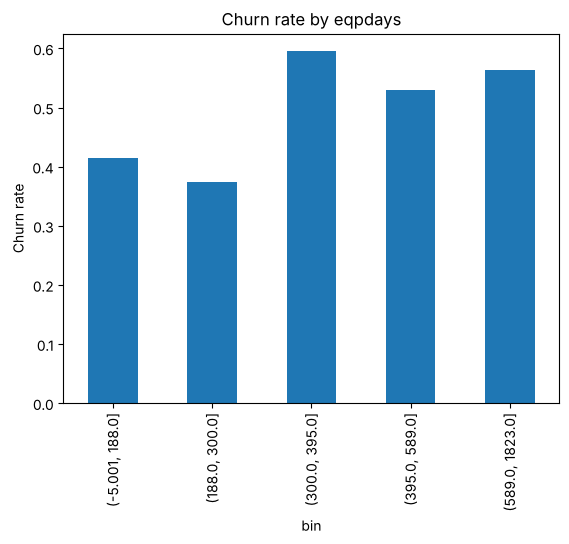

,mean,count
bin,,
"(-5.001, 188.0]",0.415325,20006
"(188.0, 300.0]",0.373817,20082
"(300.0, 395.0]",0.595278,20078
"(395.0, 589.0]",0.530401,19868
"(589.0, 1823.0]",0.563787,19965


In [8]:
churn_by_bins('eqpdays')

In [9]:
bins = [-10, 90, 180, 270, 330, 350, 365, 380, 400, 450, 540, 730, 2000]
df['eqp_bin'] = pd.cut(df['eqpdays'], bins=bins)
df.groupby('eqp_bin', observed=True)['churn'].agg(['mean', 'count'])

,mean,count
eqp_bin,,
"(-10, 90]",0.398654,9655
"(90, 180]",0.438192,8672
"(180, 270]",0.375816,16854
"(270, 330]",0.511841,12330
"(330, 350]",0.620731,4158
"(350, 365]",0.614134,3014
"(365, 380]",0.542477,2931
"(380, 400]",0.562275,3340
"(400, 450]",0.530502,6311


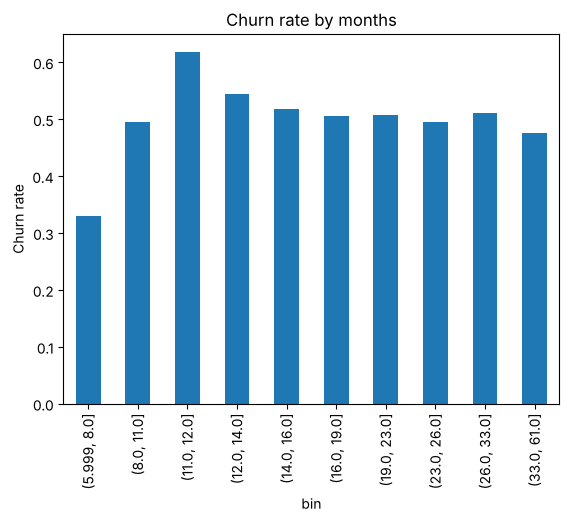

,mean,count
bin,,
"(5.999, 8.0]",0.330634,10002
"(8.0, 11.0]",0.495917,16408
"(11.0, 12.0]",0.618598,6033
"(12.0, 14.0]",0.543664,10203
"(14.0, 16.0]",0.517149,7435
"(16.0, 19.0]",0.505278,10420
"(19.0, 23.0]",0.508052,12481
"(23.0, 26.0]",0.495566,7329
"(26.0, 33.0]",0.510839,10933


In [10]:
churn_by_bins('months', q=10)

In [11]:
(df['eqpdays'] < 0).sum()

np.int64(133)

In [12]:
df['tenure_grp'] = pd.cut(df['months'], [5, 10, 13, 100], labels=['6-10', '11-13', '14+'])
df['eqp_grp'] = pd.cut(df['eqpdays'], [-10, 300, 400, 5000], labels=['<300', '300-400', '400+'])

print(pd.crosstab(df['tenure_grp'], df['eqp_grp'], values=df['churn'], aggfunc='mean').round(3))
print(pd.crosstab(df['tenure_grp'], df['eqp_grp']))

eqp_grp      <300  300-400   400+
tenure_grp                       
6-10        0.321    0.549    NaN
11-13       0.589    0.623  0.566
14+         0.411    0.521  0.547
eqp_grp      <300  300-400   400+
tenure_grp                       
6-10        16972     1409      0
11-13        4905    14374    433
14+         18211     5083  38612


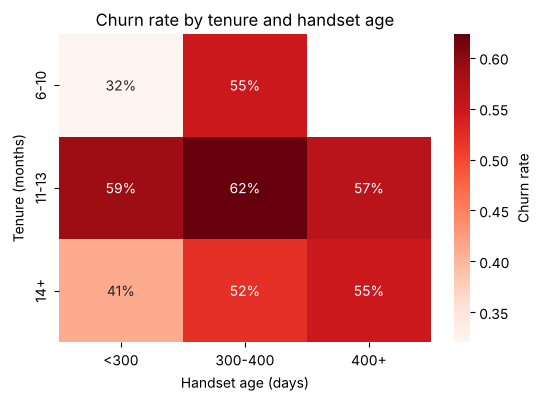

In [13]:
pivot = pd.crosstab(df['tenure_grp'], df['eqp_grp'], values=df['churn'], aggfunc='mean')
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Reds', cbar_kws={'label': 'Churn rate'})
plt.title('Churn rate by tenure and handset age')
plt.xlabel('Handset age (days)'); plt.ylabel('Tenure (months)')
plt.savefig('figures/churn_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

### Finding: Churn is highest around 12 months

**What I saw:**
- Churn rate is highest when customers are in their 11th–13th month (about 57–62%).
  Even customers with new phones leave at this time.
  This may be because many contracts end after 12 months.
- For customers who stayed more than 14 months, phone age also matters:
  - New phone (less than 300 days): 41% churn
  - Old phone (more than 400 days): 55% churn
- Two big groups:
  - Customers in month 11–13: about 19,700 people
  - Long-term customers with old phones: about 38,600 people

**What this means for the business:**
- Idea A: Give a renewal offer at month 10, before the contract ends.
- Idea B: Give a phone upgrade offer when the phone is about 300 days old.

**Limitation:**
- This only shows a relationship, not a cause.
  Customers with new phones may stay because they signed a new contract.
  The company should test the offer with an A/B test first.

In [14]:
print('Negative eqpdays:', (df['eqpdays'] < 0).sum())

Negative eqpdays: 133


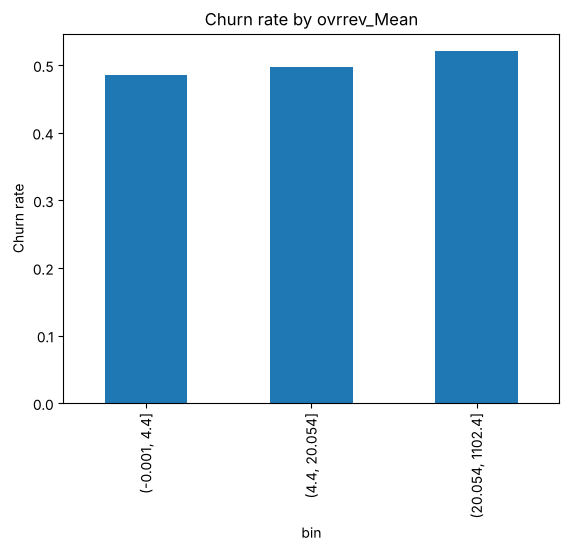

,mean,count
bin,,
"(-0.001, 4.4]",0.485788,59808
"(4.4, 20.054]",0.496735,19906
"(20.054, 1102.4]",0.520598,19929


In [15]:
churn_by_bins('ovrrev_Mean')

In [16]:
df['has_overage'] = (df['ovrrev_Mean'] > 0).astype(int)
df.groupby('has_overage')['churn'].agg(['mean', 'count'])

,mean,count
has_overage,,
0,0.491925,42909
1,0.498397,57091


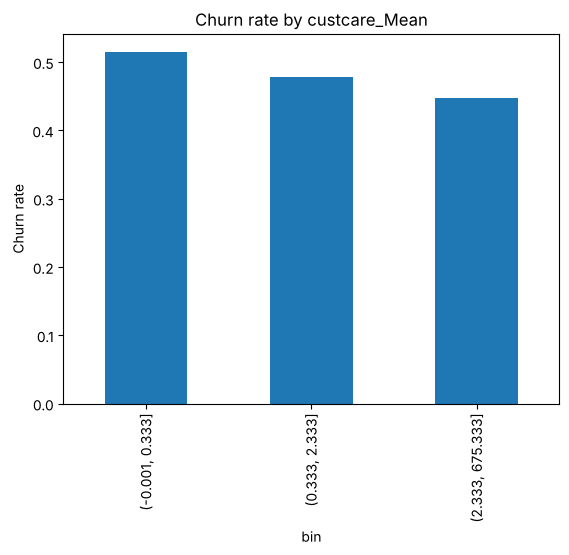

,mean,count
bin,,
"(-0.001, 0.333]",0.515364,62905
"(0.333, 2.333]",0.478218,18065
"(2.333, 675.333]",0.446873,19030


In [17]:
churn_by_bins('custcare_Mean')

In [18]:
df['called_care'] = (df['custcare_Mean'] > 0).astype(int)
df.groupby('called_care')['churn'].agg(['mean', 'count'])

,mean,count
called_care,,
0,0.517615,55692
1,0.467974,44308


In [19]:
df = df[df['eqpdays'] >= 0].copy()
print(df.shape)   

(99866, 105)


### More findings
- **Data cleaning:** 133 customers had negative phone age (`eqpdays` < 0). This is not possible, so I removed them.
- **Overage charges:** No real difference in churn (49.2% vs 49.8%). The "bill shock" idea is not supported.
- **Customer care calls:** Customers who never call customer care churn MORE (51.8%) than customers who call (46.8%).
  These may be "silent churners". They leave without complaining.
  So the company should contact customers first, not wait for them to call.
  (Limitation: customers who call may also be heavy users. I will check this later.)

### Main levers for the proposal
1. Contract timing (month 11–13)
2. Handset age (for long-term customers)
3. Proactive contact (because silent customers leave)

## 5. Problem definition
- **Business question:** Which customers will leave in the next 1 to 2 months, so the company can act early?
- **Target variable:** `churn` (1 = left 31 to 60 days after the observation date, 0 = stayed).
- **ML task:** Binary classification. The model gives each customer a churn risk score.
- **Use:** The retention team contacts the customers with the highest scores.

## 6. Preprocessing & feature engineering

In [20]:
from sklearn.model_selection import train_test_split

# Remove ID, the temporary EDA columns, and ethnicity.
# Ethnicity is removed for fairness: offers must never depend on it.
model_df = df.drop(columns=['Customer_ID', 'eqp_bin', 'tenure_grp', 'eqp_grp',
                            'has_overage', 'called_care', 'ethnic'], errors='ignore').copy()

# New features from my EDA findings
model_df['contract_window'] = model_df['months'].between(11, 13).astype(int)
model_df['eqp_tenure_ratio'] = model_df['eqpdays'] / (model_df['months'] * 30)
model_df['no_care_call'] = (model_df['custcare_Mean'] == 0).astype(int)

# Text columns -> category type
cat_cols = [c for c in model_df.columns if not pd.api.types.is_numeric_dtype(model_df[c])]
for c in cat_cols:
    model_df[c] = model_df[c].astype('category')

X = model_df.drop(columns=['churn'])
y = model_df['churn']

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)
print('Text columns:', len(cat_cols))

Train: (69906, 100) Val: (14980, 100) Test: (14980, 100)
Text columns: 20


## 7. Modeling

Logistic Regression baseline

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

num_cols = [c for c in X.columns if c not in cat_cols]

lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                   LogisticRegression(max_iter=1000))
lr.fit(X_train[num_cols], y_train)
lr_proba = lr.predict_proba(X_test[num_cols])[:, 1]

print('Logistic Regression -> AUC:', round(roc_auc_score(y_test, lr_proba), 4),
      ' Accuracy:', round(accuracy_score(y_test, lr_proba > 0.5), 4))

Logistic Regression -> AUC: 0.6366  Accuracy: 0.5923


LightGBM

In [22]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31,
                          colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
                          random_state=42, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric='auc',
         callbacks=[lgb.early_stopping(100, verbose=False)])

lgb_proba = lgbm.predict_proba(X_test)[:, 1]
print('LightGBM -> AUC:', round(roc_auc_score(y_test, lgb_proba), 4),
      ' Accuracy:', round(accuracy_score(y_test, lgb_proba > 0.5), 4),
      ' Best iteration:', lgbm.best_iteration_)

/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM -> AUC: 0.6942  Accuracy: 0.6395  Best iteration: 768


Business metric

In [23]:
def top_k_capture(y_true, proba, k=0.2):
    n = int(len(proba) * k)
    top_idx = np.argsort(proba)[::-1][:n]
    return y_true.iloc[top_idx].mean()

print('Random targeting   -> churn rate in group:', round(y_test.mean(), 3))
print('LogReg top 20%     -> churn rate in group:', round(top_k_capture(y_test, lr_proba), 3))
print('LightGBM top 20%   -> churn rate in group:', round(top_k_capture(y_test, lgb_proba), 3))

Random targeting   -> churn rate in group: 0.496
LogReg top 20%     -> churn rate in group: 0.655
LightGBM top 20%   -> churn rate in group: 0.727


Feature importance

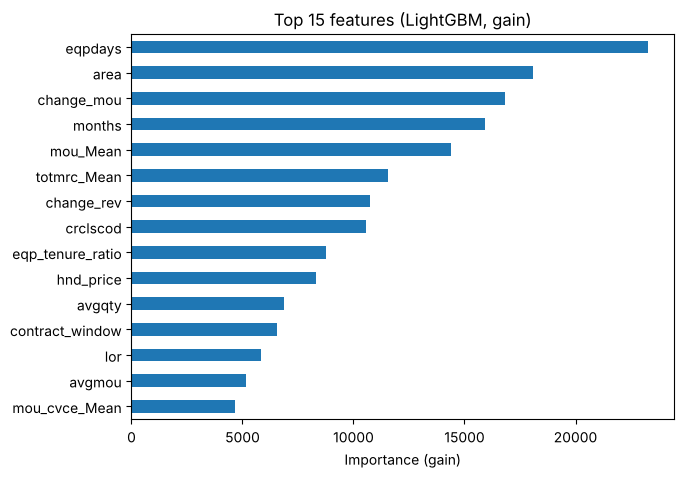

Rank out of 100 : {'eqpdays': 1, 'months': 4, 'contract_window': 12, 'eqp_tenure_ratio': 9, 'no_care_call': 99, 'custcare_Mean': 53, 'ovrrev_Mean': 36}


In [24]:
imp = pd.Series(lgbm.booster_.feature_importance(importance_type='gain'),
                index=X_train.columns).sort_values(ascending=False)

# Top 15 chart for slides
plt.figure(figsize=(7, 5))
imp.head(15)[::-1].plot(kind='barh')
plt.title('Top 15 features (LightGBM, gain)')
plt.xlabel('Importance (gain)')
plt.savefig('figures/feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

# Where do my EDA features rank?
ranks = {f: list(imp.index).index(f) + 1 for f in
         ['eqpdays', 'months', 'contract_window', 'eqp_tenure_ratio',
          'no_care_call', 'custcare_Mean', 'ovrrev_Mean']}
print('Rank out of', len(imp), ':', ranks)

### Model results
| Model | AUC | Accuracy | Churn rate in top 20% |
|---|---|---|---|
| Random | 0.50 | - | 49.6% |
| Logistic Regression | 0.637 | 0.592 | 65.5% |
| LightGBM | 0.694 | 0.640 | 72.7% |

- I chose LightGBM because it was the best on all metrics.
- Why AUC: it shows how well the model ranks high-risk customers above low-risk ones.
- Business meaning: if we give offers to the top 20% by model score,
  73% of them are real churners (random choice: only 50%).
  This is 1.5 times better than random.

### Feature importance
- `eqpdays` (phone age) is rank 1 and `months` (tenure) is rank 4.
  This matches my EDA findings.
- My new features also helped: `eqp_tenure_ratio` (rank 9), `contract_window` (rank 12).
- Customer care features are weak in the model (rank 53 and 99).
  The EDA pattern was probably caused by usage, not by care calls.
  So I will not use it as a main lever.

## 8. Evaluation
- **Model:** LightGBM
- **Metric:** ROC AUC on the test set (15% of the data, never used in training)
- **Score:** 0.694 (Logistic Regression: 0.637, random: 0.500)
- **Business metric:** 72.7% of the top 20% are real churners (random: 49.6%). This is about 1.5 times better.
- 0.694 is a moderate score. It is good for ranking customers, not for exact forecasts.

## 9. From model to business proposal
I turn the model into money in steps. First I use rough guesses. Then I replace them with numbers from sources and test different offer designs.

In [25]:
# ---------- FIRST TRY: rough guesses (later replaced with sourced numbers) ----------
N_CUSTOMERS   = 100_000   # customer base (dataset size)
REAL_CHURN    = 0.02      # real monthly churn rate     
TARGET_SHARE  = 0.20      # we contact the top 20% by model score
SUCCESS_RATE  = 0.25      # % of contacted churners we save -> needs a source
OFFER_COST    = 10        # cost of one offer (USD)       
MONTHS_KEPT   = 12        # extra months a saved customer stays

ARPU = df['rev_Mean'].median()   # monthly revenue per customer (from data)
LIFT = top_k_capture(y_test, lgb_proba) / y_test.mean()

# ---------- CALCULATION ----------
targeted        = N_CUSTOMERS * TARGET_SHARE
churners_found  = targeted * REAL_CHURN * LIFT
saved           = churners_found * SUCCESS_RATE
revenue_saved   = saved * ARPU * MONTHS_KEPT
campaign_cost   = targeted * OFFER_COST
net_benefit     = revenue_saved - campaign_cost

print(f'ARPU (median monthly revenue): ${ARPU:.1f}')
print(f'Model lift: {LIFT:.2f}x')
print(f'Customers contacted: {targeted:,.0f}')
print(f'Churners found: {churners_found:,.0f}')
print(f'Customers saved: {saved:,.0f}')
print(f'Revenue saved: ${revenue_saved:,.0f}')
print(f'Campaign cost: ${campaign_cost:,.0f}')
print(f'Net benefit: ${net_benefit:,.0f}')

ARPU (median monthly revenue): $48.2
Model lift: 1.47x
Customers contacted: 20,000
Churners found: 587
Customers saved: 147
Revenue saved: $84,765
Campaign cost: $200,000
Net benefit: $-115,235


Better impact model

 target_%  lift  contacted  saved  revenue_$  cost_$  net_$
        5  1.70       5000     42      24635   19204   5431
       10  1.57      10000     78      45496   38147   7348
       20  1.47      20000    146      84765   75865   8900
       30  1.40      30000    210     121543  113409   8133


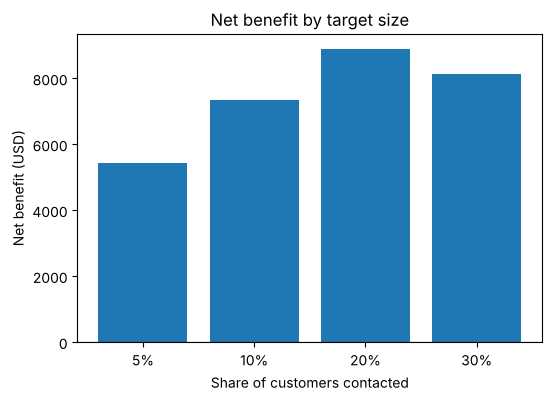

In [26]:
# ---------- SECOND TRY: better cost model, still rough guesses ----------
REAL_CHURN       = 0.02   # real monthly churn rate
SUCCESS_RATE     = 0.25   # % of contacted churners who stay because of the offer
CONTACT_COST     = 1      # SMS / call per customer (USD)
INCENTIVE        = 50     # discount or upgrade value per accepted offer (USD)
NONCHURN_ACCEPT  = 0.05   # % of non-churners who also take the offer (waste)
MONTHS_KEPT      = 12

def impact(k):
    lift      = top_k_capture(y_test, lgb_proba, k) / y_test.mean()
    targeted  = N_CUSTOMERS * k
    churners  = targeted * REAL_CHURN * lift
    saved     = churners * SUCCESS_RATE
    wasted    = (targeted - churners) * NONCHURN_ACCEPT
    revenue   = saved * ARPU * MONTHS_KEPT
    cost      = targeted * CONTACT_COST + (saved + wasted) * INCENTIVE
    return {'target_%': int(k * 100), 'lift': round(lift, 2), 'contacted': int(targeted),
            'saved': int(saved), 'revenue_$': int(revenue), 'cost_$': int(cost),
            'net_$': int(revenue - cost)}

results = pd.DataFrame([impact(k) for k in [0.05, 0.10, 0.20, 0.30]])
print(results.to_string(index=False))

# Chart for slides
plt.figure(figsize=(6, 4))
plt.bar(results['target_%'].astype(str) + '%', results['net_$'])
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Net benefit by target size')
plt.xlabel('Share of customers contacted'); plt.ylabel('Net benefit (USD)')
plt.savefig('figures/net_benefit.png', dpi=200, bbox_inches='tight')
plt.show()

Sensitivity analysis

In [27]:
rows = []
for churn in [0.01, 0.02]:
    for success in [0.13, 0.25]:
        REAL_CHURN, SUCCESS_RATE = churn, success
        best = max([impact(k) for k in [0.05, 0.10, 0.20, 0.30]], key=lambda r: r['net_$'])
        rows.append({'real_churn': f'{churn:.0%}', 'success_rate': f'{success:.0%}',
                     'best_target_%': best['target_%'], 'net_$': best['net_$']})

sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

# reset to base case
REAL_CHURN, SUCCESS_RATE = 0.01, 0.13

real_churn success_rate  best_target_%  net_$
        1%          13%              5 -11435
        1%          25%              5  -6034
        2%          13%              5  -5371
        2%          25%             20   8900


### Sensitivity analysis
- With realistic numbers (1% monthly churn, 13% success rate), a simple offer program LOSES money.
- The biggest cost is giving offers to customers who would stay anyway.
- So the problem is not the model. The problem is the offer design.
- Next, I test a better design: a cheaper contact (SMS) and an offer that
  needs a new 12-month contract.

Offer design test

In [28]:
# Realistic base case from sources
REAL_CHURN, SUCCESS_RATE = 0.01, 0.13
CONTACT_COST = 0.10   # SMS / app notification

rows = []
for inc in [10, 25, 50]:
    for acc in [0.01, 0.05]:
        INCENTIVE, NONCHURN_ACCEPT = inc, acc
        best = max([impact(k) for k in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]], key=lambda r: r['net_$'])
        rows.append({'incentive_$': inc, 'nonchurner_accept': f'{acc:.0%}',
                     'best_target_%': best['target_%'], 'saved': best['saved'],
                     'net_$': best['net_$']})

design = pd.DataFrame(rows)
print(design.to_string(index=False))

 incentive_$ nonchurner_accept  best_target_%  saved  net_$
          10                1%             50     83  37347
          10                5%             50     83  17603
          25                1%             50     83  28694
          25                5%              5     11   -515
          50                1%             50     83  14273
          50                5%              5     11  -6935


### Proposal: Contract-End Retention Program

**Who:** Top 20% of customers by model risk score, checked every month (pilot).
Scale to the top 30% if the pilot works.

**What:** An SMS or app message with a $25 offer
(bill discount, or a phone upgrade of equal cost).
The customer gets the offer only if they sign a new 12 month contract.

**When:** Every month. For customers near month 12, send it at month 10, before the churn peak.

**Expected result (per 100,000 customers, per month):**
- Pilot (top 20%): about 38 customers saved, net benefit about $14,200
- Scale (top 30%): about 54 customers saved, net benefit about $19,800
- Assumptions: 1% monthly churn, 13% save rate (from industry sources)

**Risk:** Some studies show that contacting customers can make some of them leave.
So we start with a pilot A/B test: one group gets the offer, one group does not.
We compare churn in the two groups before we scale up.

ROI table

In [29]:
REAL_CHURN, SUCCESS_RATE = 0.01, 0.13
CONTACT_COST, INCENTIVE, NONCHURN_ACCEPT = 0.10, 25, 0.01

table = pd.DataFrame([impact(k) for k in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]])
table['ROI_%'] = (table['net_$'] / table['cost_$'] * 100).round(0)
table['net_per_contact_$'] = (table['net_$'] / table['contacted']).round(2)
print(table.to_string(index=False))

 target_%  lift  contacted  saved  revenue_$  cost_$  net_$  ROI_%  net_per_contact_$
        5  1.70       5000     11       6405    2005   4399  219.0               0.88
       10  1.57      10000     20      11828    3972   7856  198.0               0.79
       20  1.47      20000     38      22038    7879  14159  180.0               0.71
       30  1.40      30000     54      31601   11761  19839  169.0               0.66
       50  1.28      50000     83      48115   19420  28694  148.0               0.57
      100  1.00     100000    130      75153   38000  37153   98.0               0.37


### Final recommendation: Contract-End Retention Program

**Phase 1: Pilot (top 20% by model score, with a control group)**
- Contact: 20,000 customers per month (SMS / app)
- Offer: $25, only if the customer signs a new 12 month contract
- Expected: 38 customers saved, net benefit $14,159 per month, ROI 180%

**Phase 2: Scale (top 30%, if the pilot works)**
- Expected: 54 customers saved, net benefit $19,839 per month, ROI 169%

**Why not contact everyone?**
- The model almost doubles benefit per contact ($0.71 vs $0.37).
- Contacting low risk customers can make some of them leave (Ascarza study).
  If only about 0.05% of the 80,000 extra customers leave because of the message,
  the extra benefit from contacting everyone is gone.

Net benefit = revenue kept minus campaign cost. It is not profit after margin.
(All numbers are per 100,000 customers, using assumptions from industry sources:
1% monthly churn, 13% save rate.)

### Why we still need the model
- With cheap SMS and a contract-linked offer, even sending to everyone looks profitable.
- But our calculation does not include the "backfire" risk:
  a study showed that contacting customers raised churn from 6% to 10% (Ascarza).
- The model helps us contact only high-risk customers.
  This gives higher return per contact and lower risk.
- Plan: start with a pilot on the top 20% (A/B test), then scale up if it works.

## 10. References

1. Nasdaq/Zacks (2026). Verizon Rides on Strength in Consumer Segment. https://www.nasdaq.com/articles/verizon-rides-strength-consumer-segment-will-it-sustain
2. PhoneArena (2026). AT&T Q4 and full year 2025 earnings. https://www.phonearena.com/news/at-t-had-better-than-expected-quarter_id177767
3. AOL / TheStreet (2026). T-Mobile plans major pricing changes after losing more customers. https://www.aol.com/articles/t-mobile-ceo-plans-major-201700146.html
4. CustomerThink. Building Customer Loyalty in Wireless Communications. https://customerthink.com/building_customer_loyalty_in_wireless/
5. Columbia Business School. Some Customers Are Best Left Alone (Ascarza). https://business.columbia.edu/insights/chazen-global-insights/some-customers-are-best-left-alone
6. Matsuo-Iwasawa Lab, University of Tokyo. GCI World 2026 Final Assignment: Company A dataset and tutorial.
7. Generative AI: Claude (Anthropic) chat history: [paste this chat's share URL]

## Charts for slides

In [30]:
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
MAIN, HIGHLIGHT, GREY = '#1f6f8b', '#e4572e', '#b8c4cc'

def add_labels(ax, fmt='{:.0%}'):
    for p in ax.patches:
        ax.annotate(fmt.format(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=11)

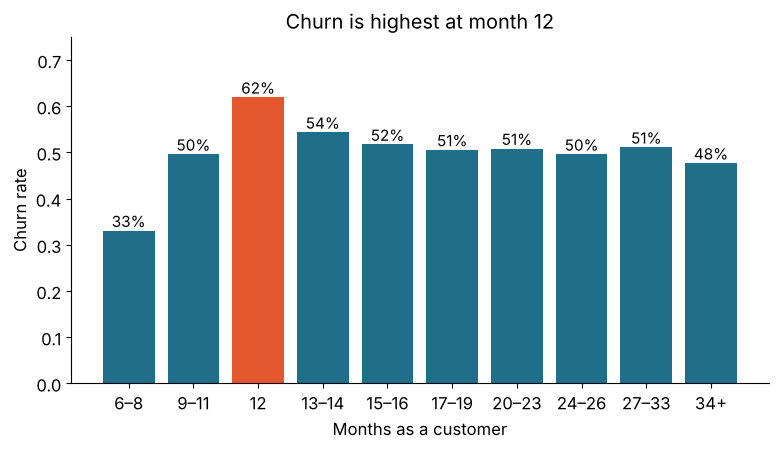

In [31]:
tmp = df[['months', 'churn']].copy()
tmp['m_bin'] = pd.cut(tmp['months'], [5, 8, 11, 12, 14, 16, 19, 23, 26, 33, 61],
                      labels=['6–8', '9–11', '12', '13–14', '15–16', '17–19',
                              '20–23', '24–26', '27–33', '34+'])
rates = tmp.groupby('m_bin', observed=True)['churn'].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(rates.index.astype(str), rates.values,
       color=[HIGHLIGHT if l == '12' else MAIN for l in rates.index.astype(str)])
add_labels(ax)
ax.set_title('Churn is highest at month 12')
ax.set_xlabel('Months as a customer'); ax.set_ylabel('Churn rate')
ax.set_ylim(0, 0.75)
plt.savefig('figures/slide5_tenure.png', dpi=200, bbox_inches='tight'); plt.show()

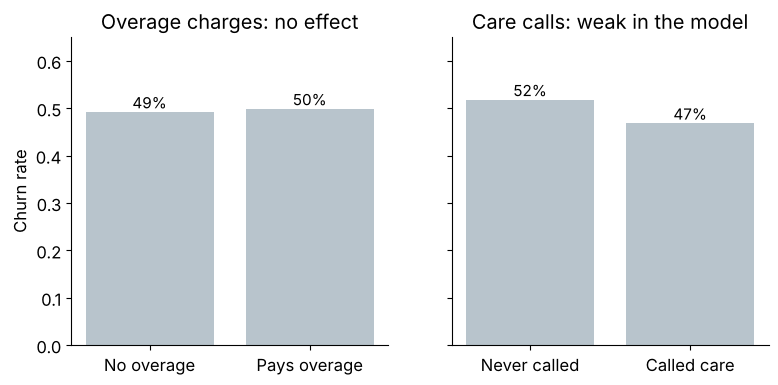

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

ov = df.groupby(df['ovrrev_Mean'] > 0)['churn'].mean()
axes[0].bar(['No overage', 'Pays overage'], ov.values, color=GREY)
axes[0].set_title('Overage charges: no effect')

cc = df.groupby(df['custcare_Mean'] > 0)['churn'].mean()
axes[1].bar(['Never called', 'Called care'], cc.values, color=GREY)
axes[1].set_title('Care calls: weak in the model')

for ax in axes:
    add_labels(ax); ax.set_ylim(0, 0.65)
axes[0].set_ylabel('Churn rate')
plt.savefig('figures/slide7_rejected.png', dpi=200, bbox_inches='tight'); plt.show()

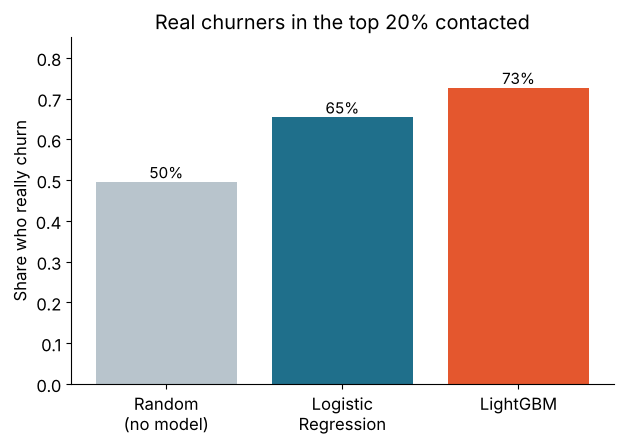

In [33]:
vals = [y_test.mean(), top_k_capture(y_test, lr_proba), top_k_capture(y_test, lgb_proba)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(['Random\n(no model)', 'Logistic\nRegression', 'LightGBM'], vals,
       color=[GREY, MAIN, HIGHLIGHT])
add_labels(ax)
ax.set_title('Real churners in the top 20% contacted')
ax.set_ylabel('Share who really churn'); ax.set_ylim(0, 0.85)
plt.savefig('figures/slide11_targeting.png', dpi=200, bbox_inches='tight'); plt.show()

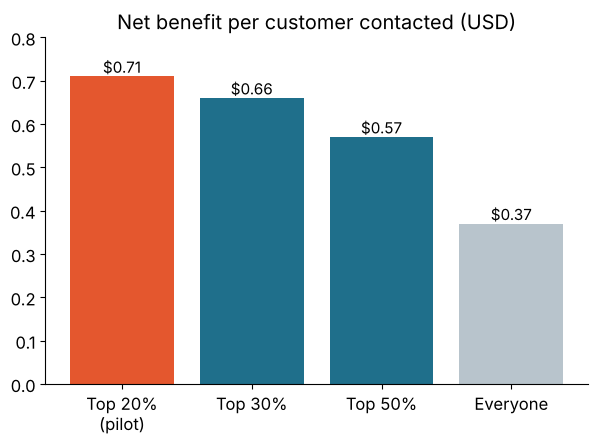

In [34]:
# Slide 13 chart: net benefit per customer contacted
sub = table[table['target_%'].isin([20, 30, 50, 100])]
labels = ['Top 20%\n(pilot)', 'Top 30%', 'Top 50%', 'Everyone']
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(labels, sub['net_per_contact_$'], color=[HIGHLIGHT, MAIN, MAIN, GREY])
add_labels(ax, fmt='${:.2f}')
ax.set_title('Net benefit per customer contacted (USD)')
ax.set_ylim(0, 0.8)
plt.savefig('figures/slide13_net_per_contact.png', dpi=200, bbox_inches='tight'); plt.show()